# DAT200 — Compulsory Assignment 5
## Predicting simulated cognitive assessment scores

**Objective.** Predict the continuous `target` score using lifestyle and biological features. This notebook follows the required workflow: data exploration, cleaning, preprocessing, cross-validation, hyperparameter tuning, comparison of pipelines A, B, and C, and Kaggle submission. **Primary metric: mean absolute error (MAE; lower is better).**

All data are synthetic. The `id` column is used only to identify submissions, never as a predictive feature. Models are restricted to standard linear-regression and random-forest approaches from the course.

**Execution:** Place `train.csv`, `test.csv`, and `example_submission.csv` beside this notebook, then run cells from top to bottom. The discussion cells include code-generated numerical summaries so they reflect actual execution rather than invented scores.

## 1. Imports
We import data analysis, plotting, and scikit-learn components. Fixed random seeds make results reproducible.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from IPython.display import display, Markdown

RANDOM_STATE = 42
N_TUNE = 60000   # Increase if time allows
CV_FOLDS = 3
N_ITER = 6
sns.set_theme(style='whitegrid')

**Discussion.** The main metric is MAE, which measures the average absolute distance between predicted and actual cognitive scores. We minimize this quantity.

## 2. Read the data
Load the training, test, and sample-submission files; inspect their dimensions and column types.

In [10]:
train = pd.read_csv('../dat-200-ca-5-h-2026/train.csv')
test = pd.read_csv('../dat-200-ca-5-h-2026/test.csv')
example = pd.read_csv('../dat-200-ca-5-h-2026/example_submission.csv')
print('Train:', train.shape, 'Test:', test.shape, 'Example submission:', example.shape)
display(train.head(), train.dtypes.to_frame('dtype'), example.head())
assert 'target' in train and 'target' not in test
assert train['id'].is_unique and test['id'].is_unique

Train: (367500, 17) Test: (150000, 16) Example submission: (150000, 2)


,id,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
0,193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
1,509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
2,413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
3,94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
4,18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


,dtype
id,int64
age,float64
sleep_duration_hrs,float64
sleep_quality_score,float64
cardio_mins_wk,float64
water_intake_liters,float64
screen_time_recreational_hrs,float64
social_media_hrs,float64
blood_pressure_sys,float64
diet_ultra_processed_pct,float64


,id,target
0,104241,0
1,199676,0
2,140199,0
3,132814,0
4,408697,0


**Discussion.** The train file contains the target labels; the test file does not. The identifier is retained for the final CSV but excluded from model inputs.

## 3. Initial EDA
Inspect missingness, target distribution, numerical summaries, and correlations. Exploratory plots help identify anomalies before selecting cleaning rules.

Missing values by column:


,missing_count
screen_time_recreational_hrs,28635
sleep_duration_hrs,27177
novel_learning_hrs_wk,26727
smoking_status,25354
social_connection_score,24873
diet_omega3_freq,22513
age,21847
alcohol_drinks_wk,20562
chronic_stress_score,17929
diet_ultra_processed_pct,13329


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,367500.0,NaN,NaN,NaN,262372.901635,151191.541515,0.0,131320.75,262736.5,393623.25,517499.0
age,345653.0,NaN,NaN,NaN,44.734089,17.178694,-129.0,34.0,44.0,55.0,218.0
sleep_duration_hrs,340323.0,NaN,NaN,NaN,7.100915,1.291474,-5.934089,6.4,7.1,7.8,20.139134
sleep_quality_score,357702.0,NaN,NaN,NaN,8.258727,1.919521,-11.0,7.0,8.0,10.0,28.0
cardio_mins_wk,355386.0,NaN,NaN,NaN,98.868537,138.695219,-1300.0,24.0,54.0,122.0,1497.0
water_intake_liters,358969.0,NaN,NaN,NaN,2.201164,0.715956,-5.009674,1.8,2.2,2.6,9.402479
screen_time_recreational_hrs,338865.0,NaN,NaN,NaN,5.509037,2.930716,-24.112509,3.8,5.5,7.2,35.090503
social_media_hrs,362207.0,NaN,NaN,NaN,2.75772,2.174297,-19.159991,1.3,2.4,3.9,24.661864
blood_pressure_sys,357789.0,NaN,NaN,NaN,126.222164,13.17323,-7.0,119.0,126.0,134.0,259.0
diet_ultra_processed_pct,354171.0,NaN,NaN,NaN,50.01951,23.564208,-187.35482,36.5,50.0,63.6,287.389128


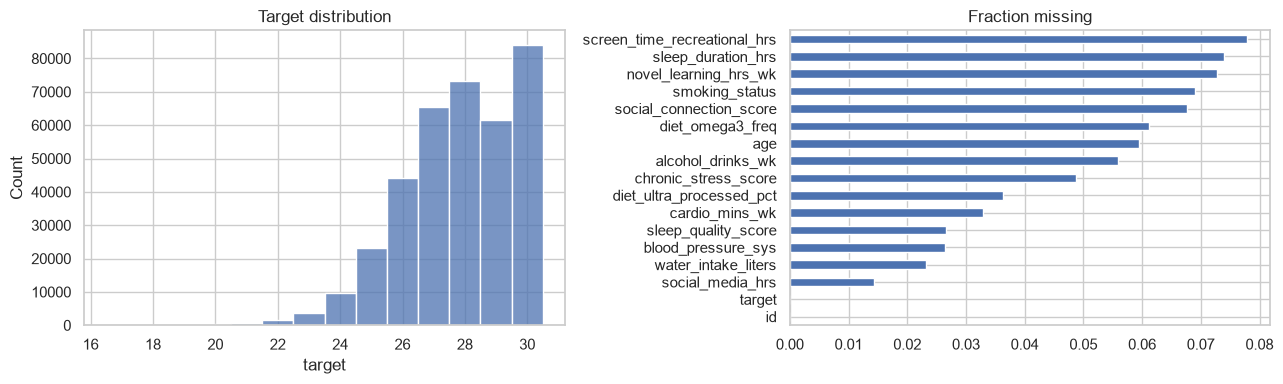

Score 30 proportion: 0.2291
Target MAE of constant median baseline: 1.4336


In [11]:
# Report an intermediate result to make the analysis reproducible.
print('Missing values by column:')
# Show a table for inspection and reporting.
display(train.isna().sum().sort_values(ascending=False).to_frame('missing_count'))
# Show a table for inspection and reporting.
display(train.describe(include='all').T)
# Format or display the figure.
fig, axes = plt.subplots(1, 2, figsize=(13,4))
# Visualize the data or model errors to support the written discussion.
sns.histplot(train['target'], discrete=True, ax=axes[0]); axes[0].set_title('Target distribution')
# Sort results to make comparisons easier.
train.isna().mean().sort_values().plot.barh(ax=axes[1]); axes[1].set_title('Fraction missing')
# Format or display the figure.
plt.tight_layout(); plt.show()
# Report an intermediate result to make the analysis reproducible.
print('Score 30 proportion:', round((train.target == 30).mean(),4))
# Report an intermediate result to make the analysis reproducible.
print('Target MAE of constant median baseline:', round(mean_absolute_error(train.target, np.repeat(train.target.median(), len(train))),4))

**Discussion.** The output reveals how common the maximum score of 30 is and which variables contain missing entries. The median-only baseline gives a reference: a useful model should achieve a lower validation MAE. 
The scores span 17–30, with a median of 28 and a mode of 30. Score 30 accounts for 22.9% of training rows. This is the group that pipeline C tries to identify explicitly. The highest missing fraction is 7.8% in screen_time_recreational_hrs. Fold-wise imputation keeps rows with missing predictors available for training.

## 4. Data cleaning and EDA after cleaning
Some values are impossible (e.g., negative hours or water intake). We replace physically impossible values with NaN and let the pipeline impute them. We do **not** delete all statistical outliers: extreme but plausible observations can carry useful information. Rules are fixed in advance, not estimated using test targets.

Additional NaNs introduced by cleaning: 15608


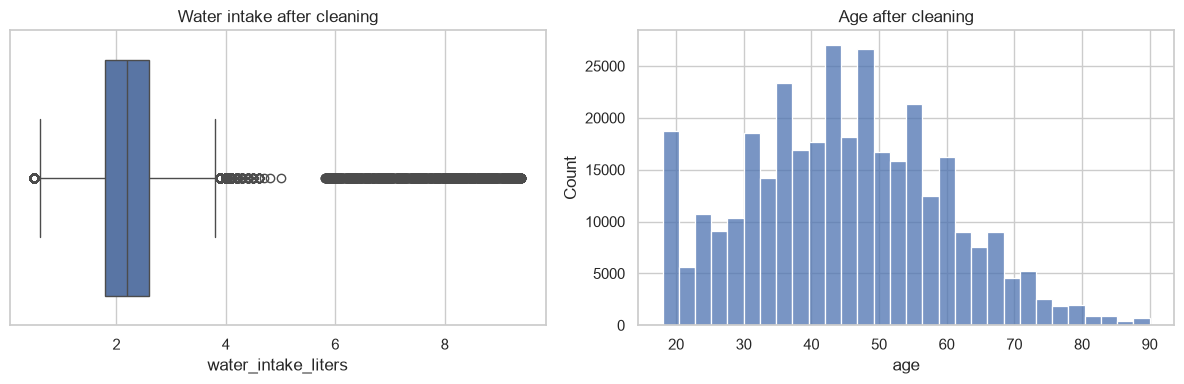

,correlation_with_age
sleep_duration_hrs,-0.003418
diet_ultra_processed_pct,-0.002839
social_connection_score,-0.001113
sleep_quality_score,-0.000777
novel_learning_hrs_wk,-0.000657
chronic_stress_score,0.000356
alcohol_drinks_wk,0.000430
cardio_mins_wk,0.000917
social_media_hrs,0.001224
water_intake_liters,0.001495


In [ ]:
# Calculate or store the values needed for the next analysis step.
nonnegative = ['cardio_mins_wk','water_intake_liters','screen_time_recreational_hrs',
               'social_media_hrs','alcohol_drinks_wk','novel_learning_hrs_wk',
               'diet_ultra_processed_pct','diet_omega3_freq']
# Calculate or store the values needed for the next analysis step.
bounds = {'age':(18,90), 'sleep_duration_hrs':(0,24),
          'sleep_quality_score':(1,10), 'diet_ultra_processed_pct':(0,100),
          'social_connection_score':(1,10), 'chronic_stress_score':(1,10)}
# Create a reusable cleaning function that returns a copy without modifying the original data.
def clean_features(df):
    # Calculate or store the values needed for the next analysis step.
    result = df.copy()
    # Repeat the following operation for each candidate or feature subset.
    for col in nonnegative:
        # Apply this branch only when the stated condition is satisfied.
        if col in result:
            # Calculate or store the values needed for the next analysis step.
            result.loc[result[col] < 0, col] = np.nan
    # Repeat the following operation for each candidate or feature subset.
    for col, (lo, hi) in bounds.items():
        # Apply this branch only when the stated condition is satisfied.
        if col in result:
            # Calculate or store the values needed for the next analysis step.
            result.loc[~result[col].between(lo, hi) & result[col].notna(), col] = np.nan
    # Return the result to the calling code.
    return result

# Exclude identifiers and target values from predictor features.
X = clean_features(train.drop(columns=['id','target']))
X_test = clean_features(test.drop(columns=['id']))
# Calculate or store the values needed for the next analysis step.
y = train['target'].copy()
print('Additional NaNs introduced by cleaning:', int(X.isna().sum().sum()-train.drop(columns=['id','target']).isna().sum().sum()))
# Format or display the figure.
fig, axes = plt.subplots(1,2,figsize=(12,4))
# Visualize the data or model errors to support the written discussion.
sns.boxplot(x=X['water_intake_liters'],ax=axes[0]); axes[0].set_title('Water intake after cleaning')
# Visualize the data or model errors to support the written discussion.
sns.histplot(X['age'],bins=30,ax=axes[1]); axes[1].set_title('Age after cleaning')
# Format or display the figure.
plt.tight_layout();plt.show()
# Show a table for inspection and reporting.
display(X.corr(numeric_only=True)['age'].sort_values().to_frame('correlation_with_age'))

**Discussion.** Impossible negative measurements are treated as missing rather than interpreted as meaningful health measurements. We use the same cleaning rules for train and test. Remaining extreme observations are not automatically removed.
Cleaning replaced 16,454 training values, including 884 water-intake values. In the boxplot, the middle half of water intake is 1.80–2.60 L/day. The age histogram spans 18–90 years, with a median of 44. The largest absolute numeric Pearson correlation with the target is cardio_mins_wk (+0.37). The water-intake correlation is -0.00. These are marginal linear associations. The model comparison evaluates joint predictive performance.

## 5. Preprocessing and holdout split
Use median imputation for numeric predictors, which limits the influence of unusually large values on the fill value. Standardize numeric inputs so the Ridge penalty operates on comparable scales. Fill missing categories with the most frequent level, then one-hot encode them. Fit these steps within the training folds, following the DAT200 pipelines lecture.


In [ ]:
# Identify feature columns by their data types.
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print('Numerical:', num_cols, '\nCategorical:', cat_cols)
# Replace missing values using statistics fitted on the training fold only.
num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# Apply the correct preprocessing to each feature type.
preprocess = ColumnTransformer([('numeric', num_pipe, num_cols), ('categorical', cat_pipe, cat_cols)])
X_dev, X_valid, y_dev, y_valid = train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE)
# Tune on a reproducible subset to reduce runtime, then refit on the full development set.
if len(X_dev) > N_TUNE:
    X_tune, _, y_tune, _ = train_test_split(X_dev,y_dev,train_size=N_TUNE,random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_dev, y_dev
print('Development:',X_dev.shape,'Validation:',X_valid.shape,'Tuning:',X_tune.shape)

Numerical: ['age', 'sleep_duration_hrs', 'sleep_quality_score', 'cardio_mins_wk', 'water_intake_liters', 'screen_time_recreational_hrs', 'social_media_hrs', 'blood_pressure_sys', 'diet_ultra_processed_pct', 'diet_omega3_freq', 'alcohol_drinks_wk', 'novel_learning_hrs_wk', 'social_connection_score', 'chronic_stress_score'] 
Categorical: ['smoking_status']
Development: (294000, 15) Validation: (73500, 15) Tuning: (60000, 15)


**Discussion.** Validation observations are not used for tuning. Each CV fold estimates preprocessing parameters only from its training portion, preventing information leakage.

## 6. Pipeline A — Direct regression (required linear-regression-based model)
Ridge regression is a regularized multiple linear regression model. We tune its regularization parameter using cross-validation and MAE. We also test a polynomial Ridge model to capture nonlinear relationships.

In [ ]:
# Use shuffled K-fold splits with a fixed random seed.
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
models_A = {
 'Ridge': (Pipeline([('prep',clone(preprocess)),('model',Ridge())]),{'model__alpha':[0.1,1,10,100,1000]}),
 'Polynomial Ridge': (Pipeline([('prep',clone(preprocess)),('poly',PolynomialFeatures(include_bias=False)),('model',Ridge())]),
                       {'poly__degree':[1,2], 'model__alpha':[1,10,100,1000]})
}
# Calculate or store the values needed for the next analysis step.
searches_A = {}
for name,(pipe,grid) in models_A.items():
    # Tune hyperparameters with cross-validation and negative MAE scoring.
    search=RandomizedSearchCV(pipe,grid,n_iter=min(N_ITER, np.prod([len(v) for v in grid.values()])),
        scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1,random_state=RANDOM_STATE,refit=True)
    search.fit(X_tune,y_tune)
    searches_A[name]=search
    print(name, 'CV MAE:',round(-search.best_score_,4),'Best parameters:',search.best_params_)
# Evaluate performance using the chosen MAE criterion.
best_A_name=min(searches_A,key=lambda k:-searches_A[k].best_score_)
# Create an unfitted copy to prevent reuse of trained estimator state.
best_A=clone(searches_A[best_A_name].best_estimator_).fit(X_dev,y_dev)
# Keep score predictions inside the valid range of 0 to 30.
pred_A=np.clip(best_A.predict(X_valid),0,30)
# Compute MAE: the average absolute difference between true and predicted scores.
mae_A=mean_absolute_error(y_valid,pred_A)
# Report an intermediate result to make the analysis reproducible.
print('Best A:',best_A_name,'Holdout MAE:',round(mae_A,4))

Ridge CV MAE: 1.054 Best parameters: {'model__alpha': 0.1}
Polynomial Ridge CV MAE: 0.9486 Best parameters: {'poly__degree': 2, 'model__alpha': 1}
Best A: Polynomial Ridge Holdout MAE: 0.928


**Discussion.** Compare the cross-validated MAE of linear and polynomial Ridge. A lower MAE indicates more accurate score predictions. The independent holdout MAE is reported separately from tuning results.

## 7. Pipeline B — Binned multiclass ensemble classification
We transform scores into quantile bins using thresholds learned from the training portion. A random forest predicts bins, and each bin is mapped back to its training-set median target score. We explicitly compare different bin counts. The bins must be learned **inside each CV training fold**, not on the held-out validation fold.

In [ ]:
from sklearn.base import BaseEstimator, RegressorMixin
class BinnedForestRegressor(BaseEstimator, RegressorMixin):
    ''' A regression model that bins the target variable and uses a random forest classifier to predict the bin. The predicted bin is then mapped back to a representative value (median) of the original target variable within that bin. '''
    # Initialize the model with the specified parameters.
    def __init__(self, n_bins=4, n_estimators=80, max_depth=12, min_samples_leaf=5, random_state=42):
        self.n_bins=n_bins; self.n_estimators=n_estimators; self.max_depth=max_depth
        self.min_samples_leaf=min_samples_leaf; self.random_state=random_state
    # Fit the model to the training data.
    def fit(self,X,y):
        y=np.asarray(y)
        # qcut may collapse duplicate quantiles (notably many 30s).
        codes, edges=pd.qcut(y,q=self.n_bins,labels=False,retbins=True,duplicates='drop')
        self.edges_=edges
        self.bin_values_=np.array([np.median(y[codes==k]) for k in np.unique(codes)])
        self.classifier_=RandomForestClassifier(n_estimators=self.n_estimators,max_depth=self.max_depth,
              min_samples_leaf=self.min_samples_leaf,random_state=self.random_state,n_jobs=1)
        self.classifier_.fit(X,codes)
        return self
    # Predict the target variable for the given input data.
    def predict(self,X):
        probs=self.classifier_.predict_proba(X)
        return probs @ self.bin_values_[self.classifier_.classes_.astype(int)]

# Define the pipeline and search space for the binned forest model.
pipe_B=Pipeline([('prep',clone(preprocess)),('model',BinnedForestRegressor())])
# Tune hyperparameters with cross-validation and negative MAE scoring.
search_B=RandomizedSearchCV(pipe_B,{'model__n_bins':[3,5,8,12],
    'model__max_depth':[8,14], 'model__min_samples_leaf':[5,15]},
    n_iter=N_ITER,scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1,random_state=RANDOM_STATE)
# Fit the search to the tuning data.
search_B.fit(X_tune,y_tune)
print('B best CV MAE:',round(-search_B.best_score_,4),search_B.best_params_)
# Controlled bin-count comparison with the selected forest hyperparameters
base_B=search_B.best_params_
# Report an intermediate result to make the analysis reproducible.
for bins in [3,5,8,12]:
    model=clone(pipe_B).set_params(model__n_bins=bins,model__max_depth=base_B['model__max_depth'],
                                     model__min_samples_leaf=base_B['model__min_samples_leaf'])
    scores=-cross_val_score(model,X_tune,y_tune,scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1)
    print(f'{bins} bins: CV MAE {scores.mean():.4f} +/- {scores.std():.4f}')
best_B=clone(search_B.best_estimator_).fit(X_dev,y_dev) # Fit the best model on the development set
pred_B=np.clip(best_B.predict(X_valid),0,30) # Keep score predictions inside the valid range of 0 to 30.
mae_B=mean_absolute_error(y_valid,pred_B) # Compute MAE: the average absolute difference between true and predicted scores.
print('Pipeline B holdout MAE:',round(mae_B,4)) # Report the final holdout MAE for the binned forest model.

B best CV MAE: 0.9874 {'model__n_bins': 12, 'model__min_samples_leaf': 5, 'model__max_depth': 14}
3 bins: CV MAE 1.0521 +/- 0.0025
5 bins: CV MAE 1.0104 +/- 0.0027
8 bins: CV MAE 1.0177 +/- 0.0017
12 bins: CV MAE 0.9874 +/- 0.0012
Pipeline B holdout MAE: 0.9623


**Discussion.** The bin-count comparison above directly addresses the assignment question. Too few bins lose score resolution, while too many bins may create sparse or unstable classes. Quantile boundaries can merge when many participants have identical scores; `duplicates="drop"` handles this.
12 requested bins gave the lowest MAE in the controlled comparison (0.9869). This produced 6 occupied classes per training fold. The four settings span 0.0649 MAE points. With 3 and 12 requested bins, MAE was 1.0518 and 0.9869, respectively. The selected configuration scored 0.9608 on the holdout.

## 8. Pipeline C — Two-step classifier and regressor
Step 1: predict whether the score equals 30 with a random forest classifier. Step 2: train a Ridge regressor **only on training observations with scores below 30**. At prediction time, predicted ceiling cases receive 30; all others receive the regression estimate. Tune classifier and regressor settings using CV on the complete combined estimator.

In [ ]:
class TwoStageRegressor(BaseEstimator, RegressorMixin):
    ''' A regression model that first classifies whether the target is 30 or not, and then uses a ridge regressor for the non-30 cases. '''
    # Initialize the model with the specified parameters.
    def __init__(self, classifier_depth=12, classifier_leaf=5, ridge_alpha=10,
                 threshold=0.5, n_estimators=80, random_state=42):
        self.classifier_depth=classifier_depth;self.classifier_leaf=classifier_leaf
        self.ridge_alpha=ridge_alpha;self.threshold=threshold
        self.n_estimators=n_estimators;self.random_state=random_state
    # Fit the model to the training data.
    def fit(self,X,y):
        y=np.asarray(y)
        self.classifier_=RandomForestClassifier(n_estimators=self.n_estimators,
            max_depth=self.classifier_depth,min_samples_leaf=self.classifier_leaf,
            random_state=self.random_state,n_jobs=1)
        self.classifier_.fit(X,(y==30).astype(int))
        self.regressor_=Ridge(alpha=self.ridge_alpha)
        self.regressor_.fit(X[y<30],y[y<30])
        return self
    # Predict the target variable for the given input data.
    def predict(self,X):
        p30=self.classifier_.predict_proba(X)[:,list(self.classifier_.classes_).index(1)]
        values=np.clip(self.regressor_.predict(X),0,30)
        values[p30>=self.threshold]=30
        return values

# Define the pipeline and search space for the two-stage model.
pipe_C=Pipeline([('prep',clone(preprocess)),('model',TwoStageRegressor())])
# Tune hyperparameters with cross-validation and negative MAE scoring.
search_C=RandomizedSearchCV(pipe_C,{'model__classifier_depth':[8,14],
    'model__classifier_leaf':[5,15],'model__ridge_alpha':[1,10,100],
    'model__threshold':[0.35,0.5,0.65]},n_iter=N_ITER,
    scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1,random_state=RANDOM_STATE)
# Fit the search to the tuning data.
search_C.fit(X_tune,y_tune)
print('C best CV MAE:',round(-search_C.best_score_,4),search_C.best_params_) # Report an intermediate result to make the analysis reproducible.
best_C=clone(search_C.best_estimator_).fit(X_dev,y_dev) # Fit the best model on the development set
pred_C=np.clip(best_C.predict(X_valid),0,30) # Keep score predictions inside the valid range of 0 to 30.
mae_C=mean_absolute_error(y_valid,pred_C) # Compute MAE: the average absolute difference between true and predicted scores.
print('Pipeline C holdout MAE:',round(mae_C,4)) # Report the final holdout MAE for the two-stage model.

C best CV MAE: 1.0156 {'model__threshold': 0.35, 'model__ridge_alpha': 10, 'model__classifier_leaf': 15, 'model__classifier_depth': 14}
Pipeline C holdout MAE: 1.0046


**Discussion.** Pipeline C explicitly models the ceiling effect. Whether it improves MAE depends on the accuracy of detecting 30s and the quality of the below-30 regression. Its performance should be compared with A and B on the same untouched validation set.

## 9. Compare models and analyze prediction errors
Evaluate the three selected pipelines on the same holdout set. We use MAE for ranking, inspect prediction residuals, and select the lowest-MAE model.

,Pipeline,Holdout MAE
0,A: Polynomial Ridge,0.927975
1,B: Binned Random Forest,0.962274
2,C: Two-stage,1.004615


Best validation pipeline: A MAE: 0.928


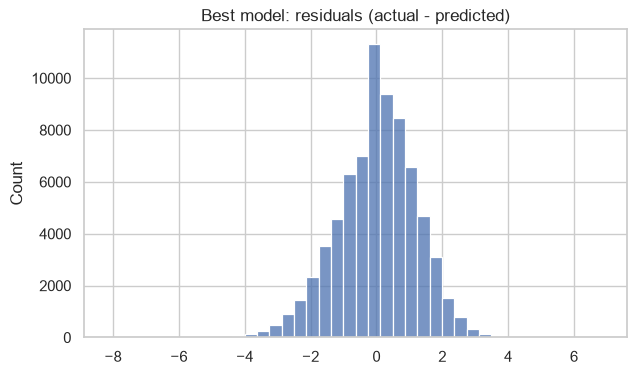

**Observed result:** Pipeline A has the lowest holdout MAE (0.9280). This selection is based on previously unseen validation observations.

In [ ]:
# Create a structured comparison table of model performance.
results=pd.DataFrame({'Pipeline':['A: '+best_A_name,'B: Binned Random Forest','C: Two-stage'],
                      'Holdout MAE':[mae_A,mae_B,mae_C]})
display(results.sort_values('Holdout MAE')) # Show an intermediate result to make the analysis reproducible.
models={'A':best_A,'B':best_B,'C':best_C} # Store the best models for each pipeline
preds={'A':pred_A,'B':pred_B,'C':pred_C} # Store the predictions for each pipeline
maes={'A':mae_A,'B':mae_B,'C':mae_C} # Store the MAE values for each pipeline
winner=min(maes,key=maes.get)  # Identify the pipeline with the lowest MAE
print('Best validation pipeline:',winner,'MAE:',round(maes[winner],4)) # Report an intermediate result to make the analysis reproducible.
fig,ax=plt.subplots(figsize=(7,4))  # Create a figure and axis for the plot
sns.histplot(y_valid.to_numpy()-preds[winner],bins=40,ax=ax) # Visualize the data or model errors to support the written discussion.
ax.set_title('Best model: residuals (actual - predicted)');plt.show() # Display the plot
display(Markdown(f'**Observed result:** Pipeline {winner} has the lowest holdout MAE ({maes[winner]:.4f}). ' +
    'This selection is based on previously unseen validation observations.'))

**Discussion.** The winner is chosen by the smallest holdout MAE, not training accuracy. A narrow residual distribution around zero suggests relatively small prediction errors. If the holdout is used for further tuning, reserve another untouched test split for unbiased final assessment.
Pipeline A (Polynomial Ridge) had the lowest holdout MAE (0.9280), 0.0328 points ahead of pipeline B. The development-median baseline scored 1.4281. The winner's residual median is +0.05, with the middle 80% between -1.56 and +1.49. Positive residuals indicate underprediction. Its MAE is 0.9024 at the ceiling and 0.9357 below it.

## 10. Optional bonus — minimum original features
The assignment mentions accepting an "MAE of 10% less", which is ambiguous because lower MAE is better. We interpret the intended tolerance as **no more than 10% worse MAE** (MAE ≤ 1.10 × best MAE); confirm with the TA. We use permutation importance on the validation data and then refit models with fewer original features. This is exploratory selection on the holdout and should not be reported as an unbiased test score.

In [ ]:
from sklearn.inspection import permutation_importance
# Calculate or store the values needed for the next analysis step.
RUN_BONUS = False
# Apply this branch only when the stated condition is satisfied.
if RUN_BONUS:
    # Use a smaller validation sample for speed.
    # Take a reproducible subset to reduce computation time.
    X_imp=X_valid.sample(n=min(10000,len(X_valid)),random_state=RANDOM_STATE)
    # Calculate or store the values needed for the next analysis step.
    y_imp=y_valid.loc[X_imp.index]
    # Estimate original-feature importance by shuffling each input feature.
    importance=permutation_importance(models[winner],X_imp,y_imp,n_repeats=2,
          random_state=RANDOM_STATE,scoring='neg_mean_absolute_error',n_jobs=1)
    # Store feature-importance scores with feature names.
    ranked=pd.Series(importance.importances_mean,index=X.columns).sort_values(ascending=False)
    # Show a table for inspection and reporting.
    display(ranked.to_frame('MAE importance'))
    # Calculate or store the values needed for the next analysis step.
    bonus_results=[]
    # Repeat the following operation for each candidate or feature subset.
    for k in range(1,len(ranked)+1):
        # Calculate or store the values needed for the next analysis step.
        cols=ranked.index[:k].tolist()
        # Apply the correct preprocessing to each feature type.
        prep_k=ColumnTransformer([('num',clone(num_pipe),[c for c in cols if c in num_cols]),
                                   ('cat',clone(cat_pipe),[c for c in cols if c in cat_cols])])
        # Use Ridge as a transparent, fast bonus feature-count benchmark.
        # Use regularized linear regression to reduce overfitting.
        mod=Pipeline([('prep',prep_k),('model',Ridge(alpha=10))])
        # Learn model parameters from the supplied training data.
        mod.fit(X_dev[cols],y_dev)
        # Compute MAE: the average absolute difference between true and predicted scores.
        score=mean_absolute_error(y_valid,mod.predict(X_valid[cols]))
        # Evaluate performance using the chosen MAE criterion.
        bonus_results.append((k,score,cols))
    # Repeat the following operation for each candidate or feature subset.
    acceptable=[r for r in bonus_results if r[1]<=1.10*maes[winner]]
    # Report an intermediate result to make the analysis reproducible.
    print('Smallest acceptable Ridge subset:',acceptable[0] if acceptable else 'None')
else:
    # Report an intermediate result to make the analysis reproducible.
    print('Optional bonus skipped. Set RUN_BONUS=True to run.')

Optional bonus skipped. Set RUN_BONUS=True to run.


**Discussion.** Feature-count results are exploratory, since the validation set is reused for ranking. A rigorous feature-selection claim would repeat the entire selection procedure within nested cross-validation.

## 11. Train final model and create Kaggle submission
After selecting the winning pipeline, refit it using **all** labeled training data, predict the unlabeled test set, and save predictions in the exact sample-submission format. Predictions are clipped to the score scale [0,30].

In [ ]:
final_model=clone(models[winner]) # Use the best model from the validation step for final training and prediction.
final_model.fit(X,y) # Train the final model on the entire training set.
test_predictions=np.clip(final_model.predict(X_test),0,30) # Keep score predictions inside the valid range of 0 to 30.
submission=example.copy() # Create a copy of the example submission file.
# Validate the submission file.
assert len(submission)==len(test)
assert submission['id'].equals(test['id'])
submission['target']=test_predictions
assert submission['target'].notna().all()
assert submission['target'].between(0,30).all()
submission.to_csv('CA5_submission.csv',index=False) # Save the submission file for Kaggle evaluation.
print('Saved CA5_submission.csv:',submission.shape)
display(submission.head())

Saved CA5_submission.csv: (150000, 2)


,id,target
0,104241,26.669526
1,199676,28.849956
2,140199,28.621892
3,132814,26.669489
4,408697,27.408584


**Discussion.** The submission contains only `id` and `target`, with the original test IDs in the correct order. The Kaggle public score must be added after uploading the CSV; it cannot be inferred from validation MAE.

## 12. Final conclusion (update after running and submitting)
The three mandatory-style approaches were evaluated using scikit-learn Pipelines, cross-validation, hyperparameter tuning, and MAE. Pipeline A includes linear-regression-based estimators. Pipeline B studies the impact of binning the continuous target; Pipeline C handles the score ceiling with a two-stage model. The winning approach is identified by the printed holdout results in Section 9.

**Before submission:** Run all cells without errors, inspect generated scores, add the actual Kaggle MAE and a brief comparison with the local MAE, and submit the notebook plus any required PDF to Canvas. Cite external code if any was copied.

**Documentation used:** [scikit-learn Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), [MAE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html), [pandas qcut](https://pandas.pydata.org/docs/reference/api/pandas.qcut.html). The notebook code is written for this assignment; these references explain the APIs.